# FCOS — експеримент 1: менший learning rate

У першому експерименті перевіряємо, чи допоможе зменшення learning rate з `1e-4` до `5e-5`. Решту параметрів залишаємо такими самими, як у baseline: три folds, 6 епох, batch size 2 та однаковий вибір кадрів. Так ми зможемо побачити вплив саме цієї зміни, а не кількох налаштувань одразу.

## 1. Налаштування експерименту

Задаємо `LR = 5e-5` і зберігаємо результати в окрему папку `fcos_lr_5e5`. Кожен fold починаємо з тих самих попередньо навчених COCO-ваг, а не з checkpoints baseline.

In [1]:
import json, re, gc, random, time, warnings, io, contextlib, shutil
from collections import defaultdict
from pathlib import Path
from zipfile import ZipFile

import numpy as np
import pandas as pd
import torch
import torchvision
from PIL import Image
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader
from torchvision import tv_tensors
from torchvision.transforms import v2 as T

SEED = 42
N_FOLDS = 3
TRAIN_FRAME_STEP = 6
VAL_FRAME_STEP = 2
EPOCHS = 6
BATCH_SIZE = 2
LR = 5e-5
NUM_CLASSES = 9
NUM_WORKERS = 0
START_FOLD = 0

ROOT = Path('/kaggle/working/fcos_lr_5e5')
ROOT.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
assert START_FOLD in range(N_FOLDS)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False

print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
print('Torch:', torch.__version__, '| Torchvision:', torchvision.__version__)
print('Experiment: FCOS LR tuning | LR:', LR, '| Output:', ROOT)
print('Inputs:')
for p in sorted(Path('/kaggle/input').iterdir()):
    print(' ', p)

GPU: Tesla T4
Torch: 2.11.0+cu130 | Torchvision: 0.26.0+cu130
Experiment: FCOS LR tuning | LR: 5e-05 | Output: /kaggle/working/fcos_lr_5e5
Inputs:
  /kaggle/input/datasets
  /kaggle/input/notebooks


## 2. Завантаження даних

Використовуємо ті самі зображення, анотації та розбиття, що й для baseline. 

In [2]:

INPUT_ROOT = Path('/kaggle/input')

PREPROCESSED_ROOT = Path(
    '/kaggle/input/datasets/alinabodnar05/preprocessed/preprocessed'
)

TRAIN_IMAGES_ROOT = Path(
    '/kaggle/input/datasets/alinabodnar05/multiple-object-video-detection-hw-2-ucu-ai-2026/train'
)

DATA_ZIP = None


if PREPROCESSED_ROOT is None:
    candidates = sorted({p.parent for p in INPUT_ROOT.rglob('train.json')
                         if (p.parent / 'folds.json').is_file()}, key=str)
    assert len(candidates) == 1, (
        'Потрібен рівно один dataset із train.json + folds.json. '
        f'Знайдено: {candidates}. Якщо їх кілька — встанови PREPROCESSED_ROOT вручну.'
    )
    PREPROCESSED_ROOT = candidates[0]

with (PREPROCESSED_ROOT / 'train.json').open(encoding='utf8') as f:
    train_data = json.load(f)
with (PREPROCESSED_ROOT / 'folds.json').open(encoding='utf8') as f:
    fold_assignments = json.load(f)

assert len(train_data) == 24201, f'Очікуємо повний train.json (24201), знайдено {len(train_data)}'
assert len(fold_assignments) == len(train_data)
assert set(fold_assignments) == {str(r['file_name']) for r in train_data}
assert set(map(int, fold_assignments.values())) == {0, 1, 2}
for key in ('file_name', 'image_id', 'boxes', 'labels', 'ignored_boxes'):
    assert key in train_data[0], f'У записах відсутнє {key}'

sample_filename = str(train_data[0]['file_name']).replace('\\', '/')

if TRAIN_IMAGES_ROOT is None and DATA_ZIP is None:
    candidates = [p for p in INPUT_ROOT.rglob('train')
                  if p.is_dir() and (p / sample_filename).is_file()]
    if len(candidates) == 1:
        TRAIN_IMAGES_ROOT = candidates[0]
    else:
        raise FileNotFoundError(
            'Не знайдено папку зі зображеннями train. Підключи dataset зі зображеннями '
            'та встанови TRAIN_IMAGES_ROOT вручну або вкажи DATA_ZIP. '
            f'Приклад file_name: {sample_filename!r}; candidates: {candidates[:5]}'
        )

if DATA_ZIP is not None:
    assert Path(DATA_ZIP).is_file(), f'ZIP не знайдено: {DATA_ZIP}'
    EXTRACT_ROOT = Path('/kaggle/working/dataset_extract')
    marker = EXTRACT_ROOT / '.train_complete'
    if not marker.exists():
        EXTRACT_ROOT.mkdir(parents=True, exist_ok=True)
        with ZipFile(DATA_ZIP) as z:
            members = [n for n in z.namelist() if n.startswith('train/') and not n.endswith('/')]
            assert members, 'В ZIP немає train/ — перевір його структуру'
            z.extractall(EXTRACT_ROOT, members=members)
        marker.touch()
    TRAIN_IMAGES_ROOT = EXTRACT_ROOT / 'train'

TRAIN_IMAGES_ROOT = Path(TRAIN_IMAGES_ROOT)
assert (TRAIN_IMAGES_ROOT / sample_filename).is_file(), (
    f'Не знайдено {sample_filename} у {TRAIN_IMAGES_ROOT}'
)
print('Preprocessed:', PREPROCESSED_ROOT)
print('Train images:', TRAIN_IMAGES_ROOT)
print('Records:', len(train_data), '| First:', sample_filename)

Preprocessed: /kaggle/input/datasets/alinabodnar05/preprocessed/preprocessed
Train images: /kaggle/input/datasets/alinabodnar05/multiple-object-video-detection-hw-2-ucu-ai-2026/train
Records: 24201 | First: images/uav0000013_00000_v/0000001.jpg


## 3. Розбиття даних на три folds

Використовуємо готове розбиття з `folds.json`. Усі кадри одного відео залишаються в одному fold, щоб модель не перевірялася на кадрах із тих самих відео, на яких навчалася. Для економії часу беремо кожен шостий кадр для навчання та кожен другий для перевірки.

In [3]:
def sequence_name(rec):
    return Path(str(rec['file_name']).replace('\\', '/')).parent.as_posix()

def frame_sort_key(rec):
    stem = Path(str(rec['file_name'])).stem
    match = re.search(r'(\d+)$', stem)
    return (int(match.group(1)), stem) if match else (float('inf'), stem)

def sample_every_n(records, step):
    by_sequence = defaultdict(list)
    for record in records:
        by_sequence[sequence_name(record)].append(record)
    selected = []
    for sequence in sorted(by_sequence):
        selected.extend(sorted(by_sequence[sequence], key=frame_sort_key)[::step])
    return selected

def fold_records(fold):
    full_train = [r for r in train_data if int(fold_assignments[r['file_name']]) != fold]
    full_val = [r for r in train_data if int(fold_assignments[r['file_name']]) == fold]
    train = sample_every_n(full_train, TRAIN_FRAME_STEP)
    val = sample_every_n(full_val, VAL_FRAME_STEP)
    train_sequences = {sequence_name(r) for r in train}
    val_sequences = {sequence_name(r) for r in val}
    assert train_sequences.isdisjoint(val_sequences)
    assert len({r['image_id'] for r in val}) == len(val)
    return train, val

for fold in range(N_FOLDS):
    tr, va = fold_records(fold)
    print(f'Fold {fold}: train={len(tr):,}, val={len(va):,}, '
          f'train clips={len({sequence_name(x) for x in tr})}, '
          f'val clips={len({sequence_name(x) for x in va})}')

Fold 0: train=2,705, val=4,044, train clips=37, val clips=19
Fold 1: train=2,706, val=4,046, train clips=37, val clips=19
Fold 2: train=2,713, val=4,024, train clips=38, val clips=18


## 4. Підготовка зображень

Тут створюємо `Dataset` і `DataLoader`, які передають зображення та розмітку моделі. Під час навчання іноді віддзеркалюємо зображення горизонтально й відповідно змінюємо рамки об'єктів. Для перевірки використовуємо зображення без випадкових перетворень.

In [4]:
class DetectionDataset(Dataset):
    def __init__(self, records, train=False):
        self.records = records
        transforms = [T.RandomHorizontalFlip(p=0.5)] if train else []
        transforms += [T.ToDtype(torch.float32, scale=True), T.ToPureTensor()]
        self.transforms = T.Compose(transforms)

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        rec = self.records[idx]
        file_name = str(rec['file_name']).replace('\\', '/')
        with Image.open(TRAIN_IMAGES_ROOT / file_name) as image:
            arr = np.asarray(image.convert('RGB')).copy()
        height, width = arr.shape[:2]
        image = tv_tensors.Image(torch.from_numpy(arr).permute(2, 0, 1))
        boxes = torch.as_tensor(rec['boxes'], dtype=torch.float32).reshape(-1, 4)
        ignored = torch.as_tensor(rec['ignored_boxes'], dtype=torch.float32).reshape(-1, 4)
        target = {
            'boxes': tv_tensors.BoundingBoxes(boxes, format='XYXY', canvas_size=(height, width)),
            'labels': torch.as_tensor(rec['labels'], dtype=torch.int64),
            'ignored_boxes': tv_tensors.BoundingBoxes(ignored, format='XYXY', canvas_size=(height, width)),
        }
        assert len(target['boxes']) == len(target['labels'])
        return self.transforms(image, target)

def collate_fn(items):
    return tuple(zip(*items))

def loaders_for_fold(fold, smoke=False):
    train_records, val_records = fold_records(fold)
    if smoke:
        train_records = train_records[:min(8, len(train_records))]
        val_records = val_records[:min(8, len(val_records))]
    train_ds = DetectionDataset(train_records, train=True)
    val_ds = DetectionDataset(val_records, train=False)
    train_loader = DataLoader(
        train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn,
        num_workers=NUM_WORKERS, pin_memory=True,
    )
    val_loader = DataLoader(
        val_ds, batch_size=1, shuffle=False, collate_fn=collate_fn,
        num_workers=NUM_WORKERS, pin_memory=True,
    )
    return train_loader, val_loader, train_records, val_records

## 5. Створення FCOS

Архітектуру моделі не змінюємо: це FCOS із ResNet-50-FPN для восьми класів. Так само враховуємо `ignored regions`, щоб не штрафувати модель за невизначені ділянки зображень. У цьому експерименті змінюється лише learning rate.

In [5]:
from torchvision.models.detection import fcos_resnet50_fpn, FCOS_ResNet50_FPN_Weights
from torchvision.models.detection.fcos import FCOSClassificationHead
from torchvision.models.detection.transform import resize_boxes
from torchvision.ops import sigmoid_focal_loss


def create_model():
    model = fcos_resnet50_fpn(weights=FCOS_ResNet50_FPN_Weights.DEFAULT)
    anchors_per_loc = model.anchor_generator.num_anchors_per_location()[0]
    model.head.classification_head = FCOSClassificationHead(
        model.backbone.out_channels, anchors_per_loc, NUM_CLASSES
    )
    return model


def apply_ignore_handling(model):
    original_resize = model.transform.resize
    original_compute_loss = model.head.compute_loss

    def resize_with_ignore(image, target=None):
        original_size = tuple(image.shape[-2:])
        result_image, result_target = original_resize(image, target)
        if result_target is not None and 'ignored_boxes' in result_target:
            result_target['ignored_boxes'] = resize_boxes(
                result_target['ignored_boxes'], original_size, tuple(result_image.shape[-2:])
            )
        return result_image, result_target

    def loss_with_ignore(targets, outputs, anchors, matched_idxs):
        losses = original_compute_loss(targets, outputs, anchors, matched_idxs)
        cls_logits = outputs['cls_logits']
        neg_ignored_loss = cls_logits.sum() * 0.0
        num_foreground = sum(int((idx >= 0).sum().item()) for idx in matched_idxs)

        for i, target in enumerate(targets):
            ignored_boxes = target['ignored_boxes']
            if ignored_boxes.numel() == 0:
                continue
            anchor_centers = (anchors[i][:, :2] + anchors[i][:, 2:]) * 0.5
            inside = torch.zeros(len(anchor_centers), dtype=torch.bool,
                                 device=anchor_centers.device)
            for box in ignored_boxes:
                inside |= ((anchor_centers[:, 0] >= box[0]) &
                           (anchor_centers[:, 0] <= box[2]) &
                           (anchor_centers[:, 1] >= box[1]) &
                           (anchor_centers[:, 1] <= box[3]))
            inside &= (matched_idxs[i] < 0)
            if inside.any():
                logits = cls_logits[i][inside]
                neg_ignored_loss = neg_ignored_loss + sigmoid_focal_loss(
                    logits, torch.zeros_like(logits), reduction='sum'
                )
        losses['classification'] = losses['classification'] - neg_ignored_loss / max(1, num_foreground)
        return losses

    model.transform.resize = resize_with_ignore
    model.head.compute_loss = loss_with_ignore
    return model

## 6. Оцінювання моделі

Після навчання перевіряємо модель на відкладених відео за COCO-метриками. `Ignored regions` враховуємо як області, що не повинні створювати зайвих штрафів під час оцінювання. Спочатку зберігаємо передбачення, а потім обчислюємо mAP та AP для об'єктів різного розміру.

In [6]:
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

CLASS_NAMES = {1:'person', 2:'bicycle', 3:'car', 4:'van', 5:'truck',
               6:'tricycle', 7:'bus', 8:'motor'}

def xyxy_to_xywh(box):
    x1, y1, x2, y2 = map(float, box)
    return [x1, y1, max(0.0, x2-x1), max(0.0, y2-y1)]

def build_coco_gt(records):
    images, annotations = [], []
    ann_id = 1
    for rec in records:
        image_id = int(rec['image_id'])
        images.append({'id':image_id, 'file_name':rec['file_name']})
        for box, label in zip(rec['boxes'], rec['labels']):
            bbox = xyxy_to_xywh(box)
            if bbox[2] <= 0 or bbox[3] <= 0: continue
            annotations.append({
                'id':ann_id, 'image_id':image_id, 'category_id':int(label),
                'bbox':bbox, 'area':bbox[2]*bbox[3], 'iscrowd':0
            })
            ann_id += 1
        for box in rec['ignored_boxes']:
            bbox = xyxy_to_xywh(box)
            if bbox[2] <= 0 or bbox[3] <= 0: continue
            for label in CLASS_NAMES:
                annotations.append({
                    'id':ann_id, 'image_id':image_id, 'category_id':label,
                    'bbox':bbox, 'area':bbox[2]*bbox[3], 'iscrowd':1
                })
                ann_id += 1
    gt = COCO()
    gt.dataset = {
        'images':images, 'annotations':annotations,
        'categories':[{'id':k,'name':v} for k,v in CLASS_NAMES.items()],
        'info':{},'licenses':[]
    }
    gt.createIndex()
    return gt

def save_predictions(model, loader, records, folder):
    pred_path = folder / 'predictions_quick.json'
    time_path = folder / 'inference_times.json'
    if pred_path.is_file() and time_path.is_file():
        print('Predictions уже збережені:', folder)
        return
    model.eval()
    predictions, durations = [], []
    with torch.inference_mode():
        for k, (images, _) in enumerate(tqdm(loader, total=len(records), desc='Validation', leave=False)):
            imgs = [im.to(DEVICE, non_blocking=True) for im in images]
            torch.cuda.synchronize()
            t0 = time.perf_counter()
            outputs = model(imgs)
            torch.cuda.synchronize()
            durations.append(time.perf_counter() - t0)
            for out in outputs:
                image_id = int(records[k]['image_id'])
                for box, label, score in zip(
                    out['boxes'].cpu().tolist(),
                    out['labels'].cpu().tolist(),
                    out['scores'].cpu().tolist(),
                ):
                    label = int(label)
                    if label not in CLASS_NAMES: continue
                    bbox = xyxy_to_xywh(box)
                    if bbox[2] <= 0 or bbox[3] <= 0: continue
                    predictions.append({
                        'image_id':image_id, 'category_id':label,
                        'bbox':bbox, 'score':float(score)
                    })
    pred_path.write_text(json.dumps(predictions), encoding='utf8')
    time_path.write_text(json.dumps({
        'seconds_per_image':durations,
        'images_evaluated':len(records)
    }), encoding='utf8')
    print('Predictions saved:', pred_path, '| detections:', len(predictions))

def score_predictions(folder, records):
    metrics_path = folder / 'metrics_quick.json'
    if metrics_path.is_file():
        return json.loads(metrics_path.read_text(encoding='utf8'))
    predictions = json.loads((folder/'predictions_quick.json').read_text(encoding='utf8'))
    times = json.loads((folder/'inference_times.json').read_text(encoding='utf8'))
    gt = build_coco_gt(records)
    if predictions:
        dt = gt.loadRes(predictions)
        ev = COCOeval(gt, dt, iouType='bbox')
        ev.params.imgIds = [int(r['image_id']) for r in records]
        ev.params.catIds = list(CLASS_NAMES)
        ev.params.maxDets = [1, 10, 100]
        with contextlib.redirect_stdout(io.StringIO()) as capture:
            ev.evaluate(); ev.accumulate(); ev.summarize()
        print(capture.getvalue().split('Average Precision')[1][:190].strip())
        values = [float(x) for x in ev.stats]
    else:
        values = [0.0] * 12
    ms = float(np.mean(times['seconds_per_image']) * 1000)
    metrics = {
        'mAP': values[0], 'AP50': values[1], 'AP75': values[2],
        'AP_small': values[3], 'AP_medium': values[4], 'AP_large': values[5],
        'inference_ms_per_image': ms,
        'FPS_equivalent_batch1': 1000.0/ms if ms > 0 else 0,
        'images_evaluated': len(records), 'num_predictions': len(predictions),
    }
    metrics_path.write_text(json.dumps(metrics, indent=2), encoding='utf8')
    print('Metrics saved:', metrics_path)
    return metrics

## 7. Навчання та checkpoints

Для кожного fold створюємо нову модель з COCO-pretrained weights. Після кожної епохи зберігаємо checkpoint, щоб за потреби продовжити саме цей експеримент, не починаючи все з нуля.

In [7]:
def train_one_fold(model, optimizer, scaler, loader, folder, fold):
    checkpoint_path = folder / 'fold_latest.pth'
    start_epoch = 0
    losses_history = []

    if checkpoint_path.is_file():
        checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=True)
        expected = {'fold':fold, 'lr':LR, 'epochs':EPOCHS,
                    'train_frame_step':TRAIN_FRAME_STEP, 'val_frame_step':VAL_FRAME_STEP}
        for key, value in expected.items():
            assert checkpoint.get(key) == value, f'Checkpoint mismatch: {key}'
        model.load_state_dict(checkpoint['model'])
        optimizer.load_state_dict(checkpoint['optimizer'])
        scaler.load_state_dict(checkpoint['scaler'])
        start_epoch = int(checkpoint['epoch'])
        losses_history = list(checkpoint['train_losses'])
        print(f'Fold {fold}: resume from epoch {start_epoch}/{EPOCHS}')

    for epoch in range(start_epoch, EPOCHS):
        model.train()
        running = 0.0
        seen = 0
        for images, targets in tqdm(loader, desc=f'Fold {fold} · Epoch {epoch+1}/{EPOCHS}', leave=False):
            images = [im.to(DEVICE, non_blocking=True) for im in images]
            targets = [{k: v.to(DEVICE) for k,v in t.items()} for t in targets]
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast('cuda', enabled=True):
                parts = model(images, targets)
                loss = sum(parts.values())
            if not torch.isfinite(loss):
                raise RuntimeError(f'Non-finite loss: fold={fold}, epoch={epoch+1}')
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            seen += len(images)
            running += float(loss.item()) * len(images)
        avg_loss = running / seen
        losses_history.append(avg_loss)
        payload = {
            'fold':fold, 'epoch':epoch+1, 'model':model.state_dict(),
            'optimizer':optimizer.state_dict(), 'scaler':scaler.state_dict(),
            'train_losses':losses_history,
            'lr':LR, 'epochs':EPOCHS, 'batch_size':BATCH_SIZE, 'seed':SEED,
            'train_frame_step':TRAIN_FRAME_STEP, 'val_frame_step':VAL_FRAME_STEP,
            'smoke_test':False
        }
        temp = checkpoint_path.with_suffix('.tmp')
        torch.save(payload, temp)
        temp.replace(checkpoint_path)
        print(f'Fold {fold} | epoch {epoch+1}/{EPOCHS} | loss={avg_loss:.4f} | checkpoint saved', flush=True)

    return losses_history


## 8. Навчання та оцінювання

Послідовно навчаємо всі три folds протягом шести епох. Після кожного навчання отримуємо передбачення на validation і рахуємо COCO-метрики. Усі результати записуються окремо від baseline.

In [8]:
all_fold_metrics = []

for FOLD in range(START_FOLD, N_FOLDS):
    folder = ROOT / f'fold_{FOLD}'
    folder.mkdir(parents=True, exist_ok=True)
    train_loader, val_loader, train_records, val_records = loaders_for_fold(FOLD, smoke=False)

    if (folder/'metrics_quick.json').is_file():
        print(f'Fold {FOLD}: completed; skipping training and evaluation')
        metrics = json.loads((folder/'metrics_quick.json').read_text(encoding='utf8'))
        all_fold_metrics.append({'fold':FOLD, **metrics})
        continue

    model = apply_ignore_handling(create_model()).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
    scaler = torch.amp.GradScaler('cuda')
    losses = train_one_fold(model, optimizer, scaler, train_loader, folder, FOLD)
    assert len(losses) == EPOCHS

    (folder/'config.json').write_text(json.dumps({
        'experiment':'lr_5e-5', 'fold':FOLD, 'epochs':EPOCHS, 'lr':LR,
        'batch_size':BATCH_SIZE, 'seed':SEED,
        'train_frame_step':TRAIN_FRAME_STEP, 'val_frame_step':VAL_FRAME_STEP,
        'num_classes':8, 'pretrained':'FCOS_ResNet50_FPN_Weights.DEFAULT',
        'ignored_regions':'negative classification locations suppressed',
        'validation_images':len(val_records), 'max_dets':100,
    }, indent=2), encoding='utf8')
    (folder/'fold_records.json').write_text(json.dumps({
        'image_ids':[int(r['image_id']) for r in val_records],
        'files':[r['file_name'] for r in val_records],
    }), encoding='utf8')

    save_predictions(model, val_loader, val_records, folder)
    metrics = score_predictions(folder, val_records)
    all_fold_metrics.append({'fold':FOLD, **metrics})
    print(f'FOLD {FOLD} COMPLETE | mAP={metrics["mAP"]:.4f} | AP50={metrics["AP50"]:.4f}')

    del model, optimizer, scaler, train_loader, val_loader
    gc.collect()
    torch.cuda.empty_cache()

print('\nAll requested folds finished.')

Downloading: "https://download.pytorch.org/models/fcos_resnet50_fpn_coco-99b0c9b7.pth" to /root/.cache/torch/hub/checkpoints/fcos_resnet50_fpn_coco-99b0c9b7.pth


100%|██████████| 124M/124M [00:00<00:00, 249MB/s]


Fold 0 · Epoch 1/6:   0%|          | 0/1353 [00:00<?, ?it/s]

Fold 0 | epoch 1/6 | loss=1.1367 | checkpoint saved


Fold 0 · Epoch 2/6:   0%|          | 0/1353 [00:00<?, ?it/s]

Fold 0 | epoch 2/6 | loss=1.0317 | checkpoint saved


... (34 outputs left out)

Fold 2 · Epoch 6/6:   0%|          | 0/1357 [00:00<?, ?it/s]

Fold 2 | epoch 6/6 | loss=0.9420 | checkpoint saved


Validation:   0%|          | 0/4024 [00:00<?, ?it/s]

Predictions saved: /kaggle/working/fcos_lr_5e5/fold_2/predictions_quick.json | detections: 366806
creating index...
index created!
Loading and preparing results...
DONE (t=1.52s)
creating index...
index created!
(AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.152
Metrics saved: /kaggle/working/fcos_lr_5e5/fold_2/metrics_quick.json
FOLD 2 COMPLETE | mAP=0.1523 | AP50=0.3036

All requested folds finished.


## 9. Підсумкові результати

Збираємо метрики трьох folds в одну таблицю та обчислюємо середнє значення й стандартне відхилення. Середнє показує загальну якість моделі, а відхилення допомагає побачити, наскільки результати різняться між відео.

In [9]:
METRICS = ['mAP','AP50','AP75','AP_small','AP_medium','AP_large']
rows = []
for fold in range(N_FOLDS):
    folder = ROOT / f'fold_{fold}'
    required = ['fold_latest.pth','predictions_quick.json','inference_times.json',
                'metrics_quick.json','config.json','fold_records.json']
    missing = [name for name in required if not (folder/name).is_file()]
    if missing:
        print(f'Fold {fold}: incomplete — missing {missing}')
        continue
    ckpt = torch.load(folder/'fold_latest.pth', map_location='cpu', weights_only=True, mmap=True)
    assert ckpt['epoch'] == EPOCHS and ckpt['fold'] == fold
    del ckpt
    metrics = json.loads((folder/'metrics_quick.json').read_text(encoding='utf8'))
    rows.append({'fold':fold, **{key:metrics[key] for key in METRICS}})

assert len(rows) == N_FOLDS, 'Ще не завершено всі 3 folds!'
df = pd.DataFrame(rows).set_index('fold')
display(df.round(4))
summary = df.agg(['mean','std'])
display(summary.round(4))
df.to_csv(ROOT/'fold_metrics.csv')
summary.to_csv(ROOT/'summary.csv')
print('All 3 folds saved in:', ROOT)

,mAP,AP50,AP75,AP_small,AP_medium,AP_large
fold,,,,,,
0,0.1777,0.3534,0.1600,0.0686,0.1397,0.2713
1,0.1382,0.2693,0.1240,0.0271,0.1408,0.3039
2,0.1523,0.3036,0.1378,0.0517,0.1524,0.3016


,mAP,AP50,AP75,AP_small,AP_medium,AP_large
mean,0.1561,0.3087,0.1406,0.0492,0.1443,0.2922
std,0.0200,0.0423,0.0182,0.0209,0.0070,0.0182


All 3 folds saved in: /kaggle/working/fcos_lr_5e5


## 10. Графіки loss та порівняння з baseline

За збереженими checkpoints будуємо графіки зміни training loss. Далі порівнюємо mAP кожного fold з baseline, щоб побачити, чи менший learning rate допоміг усюди, чи лише на окремих відео. Самі baseline-метрики використовуються тільки для порівняння, а не для навчання.

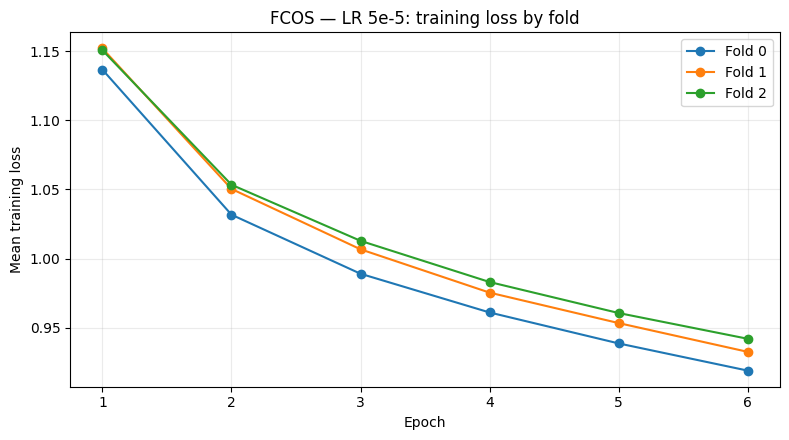

,baseline_mAP,lr_5e5_mAP,delta
0,0.1714,0.1777,0.0063
1,0.1240,0.1382,0.0142
2,0.1459,0.1523,0.0064


Baseline mean mAP ≈ 0.1471 | LR 5e-5 mean mAP = 0.1561 | Δ = +0.0090


In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4.5))
for fold in range(N_FOLDS):
    checkpoint = torch.load(ROOT / f'fold_{fold}' / 'fold_latest.pth',
                            map_location='cpu', weights_only=True, mmap=True)
    history = checkpoint['train_losses']
    plt.plot(range(1, len(history) + 1), history, marker='o', label=f'Fold {fold}')
    del checkpoint
plt.title('FCOS — LR 5e-5: training loss by fold')
plt.xlabel('Epoch')
plt.ylabel('Mean training loss')
plt.xticks(range(1, EPOCHS + 1))
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(ROOT / 'train_loss_curves.png', dpi=160)
plt.show()

baseline_map = pd.Series({0: 0.1714, 1: 0.1240, 2: 0.1459}, name='baseline_mAP')
comparison = pd.concat([baseline_map, df['mAP'].rename('lr_5e5_mAP')], axis=1)
comparison['delta'] = comparison['lr_5e5_mAP'] - comparison['baseline_mAP']
display(comparison.round(4))
print(f"Baseline mean mAP ≈ 0.1471 | LR 5e-5 mean mAP = {df['mAP'].mean():.4f} | "
      f"Δ = {df['mAP'].mean() - 0.1471:+.4f}")

## 11. Збереження результатів

Наприкінці створюємо невеликий ZIP із метриками та іншими файлами для аналізу. Великі checkpoints залишаються в окремих папках folds.

In [11]:
archive = Path('/kaggle/working/fcos_lr_5e5_metrics.zip')
with ZipFile(archive, 'w') as z:
    for fold in range(N_FOLDS):
        for name in ['metrics_quick.json','config.json','fold_records.json']:
            path = ROOT / f'fold_{fold}' / name
            assert path.is_file(), str(path)
            z.write(path, arcname=f'fold_{fold}/{name}')
    z.write(ROOT/'fold_metrics.csv', arcname='fold_metrics.csv')
    z.write(ROOT/'summary.csv', arcname='summary.csv')
    if (ROOT/'train_loss_curves.png').is_file():
        z.write(ROOT/'train_loss_curves.png', arcname='train_loss_curves.png')
print('Ready:', archive, '|', round(archive.stat().st_size/1024**2,2), 'MB')
print('Повні checkpoints лежать у', ROOT)

Ready: /kaggle/working/fcos_lr_5e5_metrics.zip | 0.63 MB
Повні checkpoints лежать у /kaggle/working/fcos_lr_5e5
